# Projeto de Big Data Analysis — II Unidade

**Problema 3:** Previsão de Demanda de Energia Elétrica (Componentes de Séries Temporais)
**Problema 13:** Previsão de Chuvas para Agricultura (Séries Temporais)

**Disciplina:** Big Data Analysis — Prof. Dr. Carlos Gustavo Pereira Moraes
**Grupo:** _(preencher nomes e matrículas)_

Os dois problemas seguem o mesmo roteiro: carregar os dados, explorar a série, decompor em componentes,
testar estacionariedade, comparar modelos de previsão e prever os próximos períodos.

**Como executar:** o notebook funciona localmente e no **Google Colab**. Se as pastas `dataset_1` (ONS) e
`dataset_2` (INMET) não existirem, os dados são baixados automaticamente das fontes oficiais. No Colab, o download
do INMET (cerca de 900 MB) leva alguns minutos.

## Configuração

In [1]:
import shutil
import urllib.request
import warnings
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.seasonal import MSTL, STL
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 4)
pd.set_option("display.float_format", "{:,.2f}".format)

ENERGY_FOLDER = Path("dataset_1")
RAIN_FOLDER = Path("dataset_2")
ENERGY_YEARS = range(2020, 2027)
RAIN_YEARS = range(2018, 2027)
ENERGY_URL = "https://ons-aws-prod-opendata.s3.amazonaws.com/dataset/curva-carga-ho/CURVA_CARGA_{year}.csv"
RAIN_URL = "https://portal.inmet.gov.br/uploads/dadoshistoricos/{year}.zip"

In [2]:
def download(url, path):
    request = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(request) as response, open(path, "wb") as file:
        shutil.copyfileobj(response, file)


def download_energy(folder, years):
    folder.mkdir(exist_ok=True)
    for year in years:
        path = folder / f"CURVA_CARGA_{year}.csv"
        if not path.exists():
            print("Baixando", path.name)
            download(ENERGY_URL.format(year=year), path)


def download_rain(folder, years):
    folder.mkdir(exist_ok=True)
    for year in years:
        target = folder / str(year)
        if not target.exists():
            print("Baixando INMET", year)
            zip_path = folder / f"{year}.zip"
            download(RAIN_URL.format(year=year), zip_path)
            with zipfile.ZipFile(zip_path) as archive:
                archive.extractall(target)
            zip_path.unlink()


download_energy(ENERGY_FOLDER, ENERGY_YEARS)
download_rain(RAIN_FOLDER, RAIN_YEARS)
print("Dados prontos.")

Dados prontos.


In [3]:
MONTHS = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"]
WEEKDAYS = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]


def mae(actual, predicted):
    return np.mean(np.abs(actual.values - predicted.values))


def rmse(actual, predicted):
    return np.sqrt(np.mean((actual.values - predicted.values) ** 2))


def mape(actual, predicted):
    mask = actual.values != 0
    return np.mean(np.abs((actual.values[mask] - predicted.values[mask]) / actual.values[mask])) * 100


def adf_test(series):
    statistic, p_value = adfuller(series.dropna())[:2]
    return {"estatística ADF": statistic, "p-valor": p_value, "estacionária": "sim" if p_value < 0.05 else "não"}


def strength(component, residual):
    return max(0, 1 - np.var(residual) / np.var(component + residual))


def future_index(series, steps):
    return pd.date_range(series.index[-1], periods=steps + 1, freq=series.index.freq)[1:]


def seasonal_naive(train, steps, period):
    values = np.resize(train.iloc[-period:].values, steps)
    return pd.Series(values, index=future_index(train, steps))


def compare_models(models, train, test):
    predictions = {name: model(train, len(test)) for name, model in models.items()}
    scores = {
        name: {"MAE": mae(test, pred), "RMSE": rmse(test, pred), "MAPE (%)": mape(test, pred)}
        for name, pred in predictions.items()
    }
    return predictions, pd.DataFrame(scores).T.sort_values("MAE")


def forecast_table(forecast, errors):
    margin = 1.96 * errors.std()
    return pd.DataFrame({"previsão": forecast, "limite inferior": forecast - margin, "limite superior": forecast + margin})


def plot_components(components, title):
    fig, axes = plt.subplots(len(components), 1, figsize=(12, 2.2 * len(components)), sharex=True)
    for ax, (name, series) in zip(axes, components.items()):
        ax.plot(series.index, series, lw=1)
        ax.set_title(name, loc="left")
    fig.suptitle(title, fontweight="bold")
    plt.tight_layout()
    plt.show()

| Função | O que faz |
|---|---|
| `download_energy`, `download_rain` | baixam os dados do ONS e do INMET quando as pastas não existem |
| `mae`, `rmse`, `mape` | erro absoluto médio, raiz do erro quadrático médio e erro percentual médio |
| `adf_test` | teste de Dickey-Fuller aumentado (H₀: a série **não** é estacionária) |
| `strength` | força de um componente: 0 = inexistente, 1 = domina a série |
| `seasonal_naive` | previsão de referência: repete o último ciclo sazonal |
| `compare_models` | treina vários modelos e calcula os erros no período de teste |
| `forecast_table` | previsão com intervalo aproximado de 95% (± 1,96 × desvio-padrão do erro de teste) |
| `plot_components` | desenha as componentes de uma decomposição |

---
## Problema 3 — Demanda de energia elétrica

**Objetivo:** decompor a demanda de energia do Brasil em **tendência + sazonalidade + resíduo** e usar essas
componentes para prever a carga dos próximos dias.

### Dados

Fonte: ONS (Operador Nacional do Sistema Elétrico), *Curva de Carga Horária*, um arquivo por ano, de 2020 a 2026.

| Coluna | Significado |
|---|---|
| `id_subsistema` | código do subsistema elétrico: `N`, `NE`, `S` ou `SE` |
| `nom_subsistema` | nome do subsistema |
| `din_instante` | **data e hora da medição** (início do intervalo de 1 hora), no horário de Brasília. Ex.: `2026-01-01 14:00:00` é a hora entre 14h e 15h |
| `val_cargaenergiahomwmed` | **carga de energia** naquela hora, em **MWmed** (megawatt médio): a energia consumida na hora dividida pela duração. 1 MWmed durante 1 hora = 1 MWh |

**Por que o Centro-Oeste aparece junto com o Sudeste?** Essa divisão não foi escolha do grupo: é como o ONS publica
os dados. O ONS não divide o país pelas 5 regiões geográficas, e sim em **4 subsistemas elétricos**, de acordo com
a rede de transmissão. O Sudeste e o Centro-Oeste formam **um único subsistema (SE/CO)**, porque as redes dessas
regiões são muito interligadas e operadas em conjunto. As grandes hidrelétricas das bacias dos rios Paraná,
Paranaíba e Grande abastecem as duas regiões pela mesma malha. Esse subsistema inclui ES, RJ, MG, SP, GO, DF, MT e
MS, além de AC e RO, que se conectam ao sistema nacional por essa mesma rede. Nos arquivos até 2025 ele se chamava
"SUDESTE" e em 2026 passou a se chamar "SUDESTE/CENTRO-OESTE", mas o código continua `SE`.

Como o objetivo é a demanda do país, a análise usa a soma dos quatro subsistemas, que é a carga do **SIN** (Sistema
Interligado Nacional).

In [4]:
def load_energy(folder):
    files = sorted(folder.glob("CURVA_CARGA_*.csv"))
    frames = [pd.read_csv(file, sep=";", parse_dates=["din_instante"]) for file in files]
    return pd.concat(frames, ignore_index=True)


def to_hourly(energy):
    hourly = energy.pivot_table(index="din_instante", columns="id_subsistema", values="val_cargaenergiahomwmed")
    hourly["SIN"] = hourly.sum(axis=1)
    hourly.index.name = "data e hora"
    return hourly.asfreq("h")


energy = load_energy(ENERGY_FOLDER)
hourly = to_hourly(energy)
load = hourly["SIN"].resample("D").mean()
load.index.name = "data"

print("Registros:", len(energy))
print("Período:", hourly.index.min(), "a", hourly.index.max())
print("Horas sem medição:", hourly["SIN"].isna().sum())
energy.head()

Registros: 241920
Período: 2020-01-01 00:00:00 a 2026-11-24 23:00:00
Horas sem medição: 0


,id_subsistema,nom_subsistema,din_instante,val_cargaenergiahomwmed
0,N,NORTE,2020-01-01 00:00:00,"4,889.15"
1,NE,NORDESTE,2020-01-01 00:00:00,"9,617.98"
2,S,SUL,2020-01-01 00:00:00,"10,013.74"
3,SE,SUDESTE,2020-01-01 00:00:00,"33,108.86"
4,N,NORTE,2020-01-01 01:00:00,"4,953.31"


In [5]:
subsystems = {"SE": "Sudeste/Centro-Oeste", "S": "Sul", "NE": "Nordeste", "N": "Norte"}
share = hourly[list(subsystems)].mean() / hourly["SIN"].mean() * 100
share.index = list(subsystems.values())
share.to_frame("participação na carga do SIN (%)")

,participação na carga do SIN (%)
Sudeste/Centro-Oeste,56.46
Sul,17.31
Nordeste,16.56
Norte,9.67


### Análise exploratória

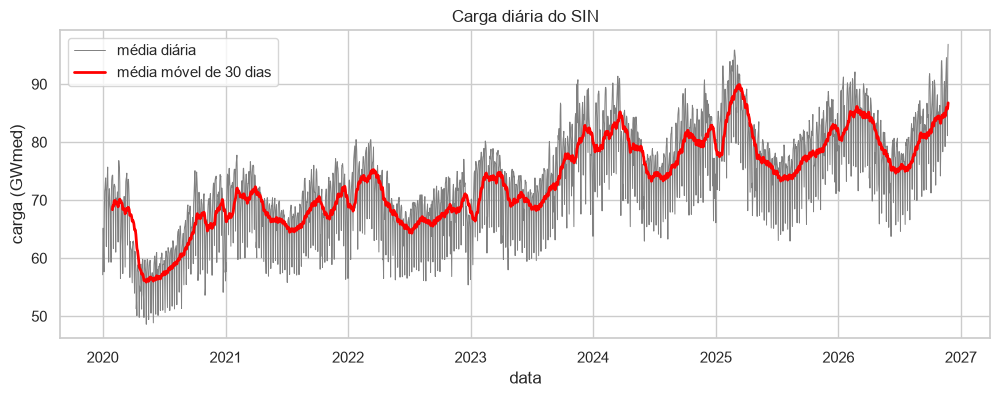

,carga média (GWmed)
ano,
2020,63.41
2021,68.53
2022,68.80
2023,73.70
2024,78.94
2025,79.61
2026,81.28


In [6]:
plt.plot(load.index, load / 1000, color="gray", lw=0.7, label="média diária")
plt.plot(load.index, load.rolling(30).mean() / 1000, color="red", lw=2, label="média móvel de 30 dias")
plt.title("Carga diária do SIN")
plt.xlabel("data")
plt.ylabel("carga (GWmed)")
plt.legend()
plt.show()

yearly = load.groupby(load.index.year).mean() / 1000
yearly.index.name = "ano"
yearly.to_frame("carga média (GWmed)")

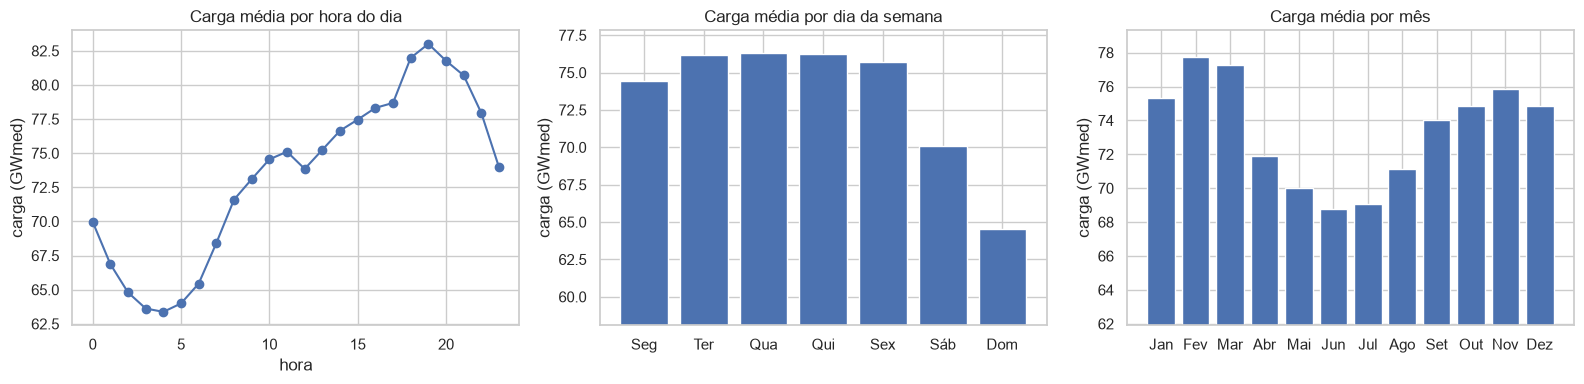

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
by_hour = hourly["SIN"].groupby(hourly.index.hour).mean() / 1000
axes[0].plot(by_hour.index, by_hour, marker="o")
axes[0].set_title("Carga média por hora do dia")
axes[0].set_xlabel("hora")

by_weekday = load.groupby(load.index.dayofweek).mean() / 1000
axes[1].bar(WEEKDAYS, by_weekday)
axes[1].set_ylim(by_weekday.min() * 0.9, by_weekday.max() * 1.02)
axes[1].set_title("Carga média por dia da semana")

by_month = load.groupby(load.index.month).mean() / 1000
axes[2].bar(MONTHS, by_month)
axes[2].set_ylim(by_month.min() * 0.9, by_month.max() * 1.02)
axes[2].set_title("Carga média por mês")
for ax in axes:
    ax.set_ylabel("carga (GWmed)")
plt.tight_layout()
plt.show()

**O que a análise exploratória mostra:**

* **Crescimento:** a carga média anual passou de **63,4 GWmed (2020)** para **79,6 GWmed (2025)**. 2020 foi afetado
  pela pandemia, com a queda de mar–mai visível no gráfico. Sem 2020, o crescimento é de cerca de **4% ao ano**.
* **Ciclo diário:** a carga mínima é por volta das **4 h** e o pico por volta das **19 h**, quando o comércio ainda
  funciona e as pessoas já estão em casa.
* **Ciclo semanal:** os dias úteis ficam em torno de 76 GWmed, o sábado em cerca de 70 GWmed e o **domingo em cerca
  de 64,5 GWmed**.
* **Ciclo anual:** a carga é maior no **verão (fev–mar)**, por causa do calor e do ar-condicionado, e menor no
  **inverno (jun–jul)**.

### Decomposição em componentes

Modelo aditivo: $Y_t = T_t + S_t + R_t$, com **T** = tendência, **S** = sazonalidade e **R** = resíduo.

É utilizado o **MSTL** (*Multiple Seasonal-Trend decomposition using Loess*), que separa **mais de uma sazonalidade ao
mesmo tempo**. Na carga diária existem duas: a **semanal** (período de 7 dias) e a **anual** (período de 365 dias).

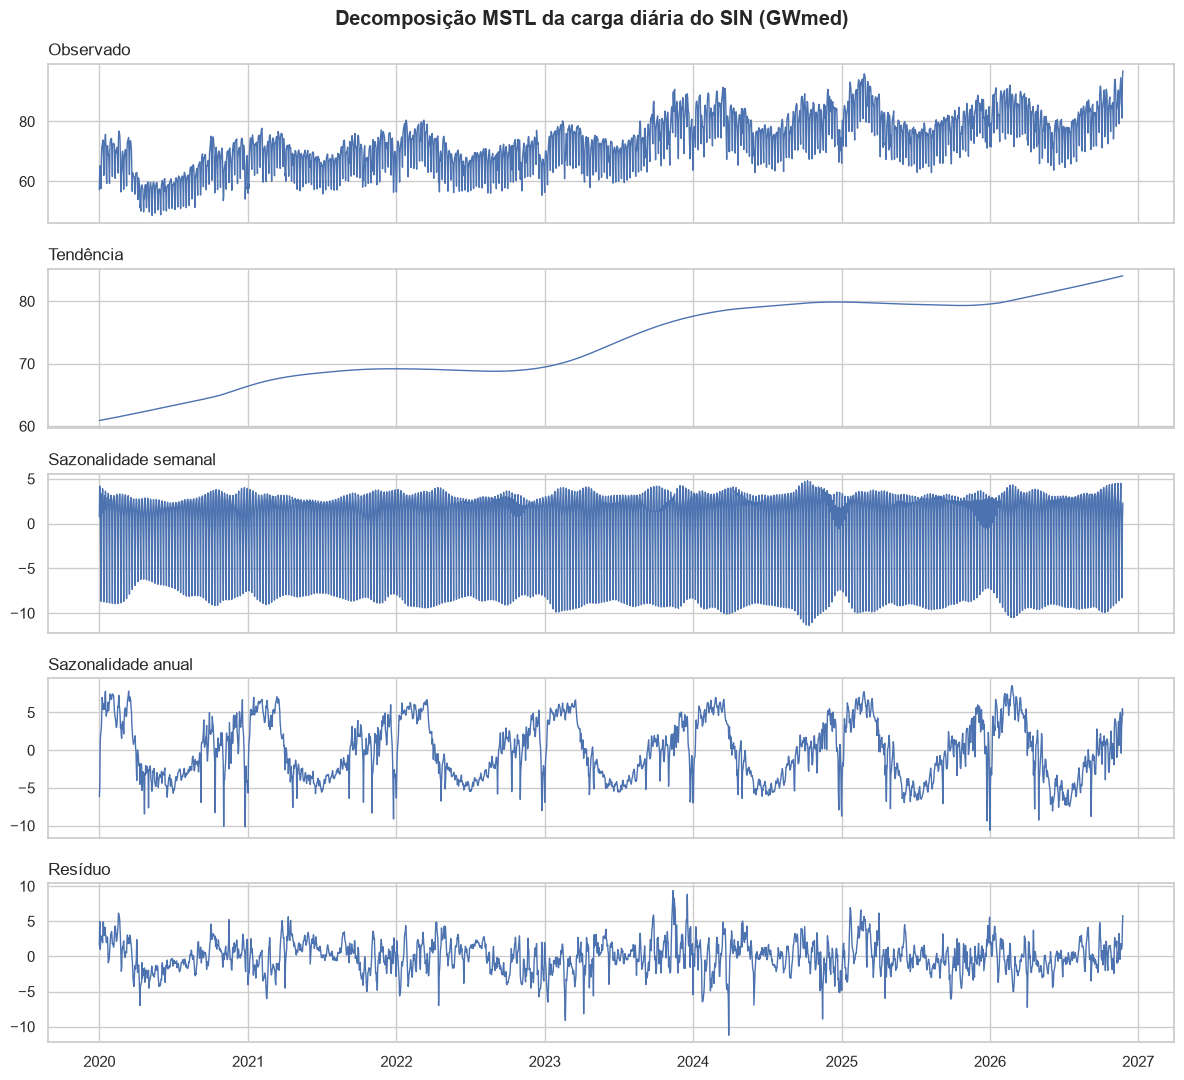

,força
tendência,0.90
sazonalidade semanal,0.79
sazonalidade anual,0.76


In [8]:
mstl = MSTL(load, periods=(7, 365)).fit()
plot_components(
    {
        "Observado": load / 1000,
        "Tendência": mstl.trend / 1000,
        "Sazonalidade semanal": mstl.seasonal["seasonal_7"] / 1000,
        "Sazonalidade anual": mstl.seasonal["seasonal_365"] / 1000,
        "Resíduo": mstl.resid / 1000,
    },
    "Decomposição MSTL da carga diária do SIN (GWmed)",
)

pd.DataFrame(
    {"força": [
        strength(mstl.trend, mstl.resid),
        strength(mstl.seasonal["seasonal_7"], mstl.resid),
        strength(mstl.seasonal["seasonal_365"], mstl.resid),
    ]},
    index=["tendência", "sazonalidade semanal", "sazonalidade anual"],
)

In [9]:
weekday_effect = mstl.seasonal["seasonal_7"].groupby(load.index.dayofweek).mean() / 1000
weekday_effect.index = WEEKDAYS
weekday_effect.to_frame("efeito em relação à tendência (GWmed)").T

,Seg,Ter,Qua,Qui,Sex,Sáb,Dom
efeito em relação à tendência (GWmed),1.05,2.77,2.98,2.92,2.37,-3.27,-8.82


**Interpretação das componentes:**

* As três componentes são fortes: força da **tendência = 0,90**, da **sazonalidade semanal = 0,79** e da
  **sazonalidade anual = 0,76**.
* **Tendência:** a carga sobe de ~61 para ~84 GWmed no período, com degraus em 2021 e em 2023–2024.
* **Sazonalidade semanal:** em relação à tendência, de terça a quinta a carga fica cerca de **+3 GWmed** acima. No
  sábado fica **−3,3 GWmed** abaixo e no domingo **−8,8 GWmed**.
* **Sazonalidade anual:** picos no verão e vales no inverno. As quedas bruscas são **feriados** (Natal, Ano-Novo e
  Carnaval).
* **Resíduo:** é pequeno, de poucos GWmed. A queda de 2020 (pandemia) aparece nele, porque não se repete.

### Estacionariedade e autocorrelação

In [10]:
pd.DataFrame(
    [adf_test(load), adf_test(load.diff(7))],
    index=["carga diária", "carga com diferença sazonal (7 dias)"],
)

,estatística ADF,p-valor,estacionária
carga diária,-1.50,0.53,não
carga com diferença sazonal (7 dias),-12.36,0.00,sim


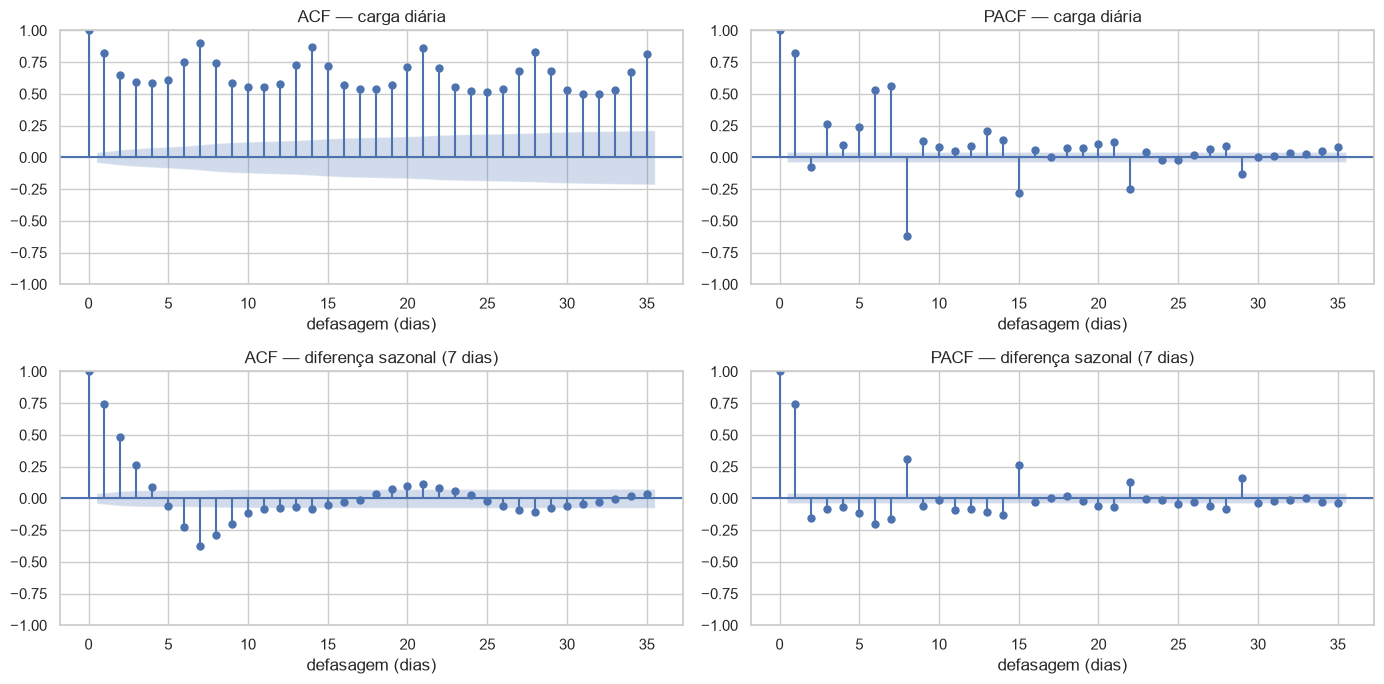

In [11]:
seasonal_difference = load.diff(7).dropna()
fig, axes = plt.subplots(2, 2, figsize=(14, 7))
plot_acf(load, lags=35, ax=axes[0, 0], title="ACF — carga diária")
plot_pacf(load, lags=35, ax=axes[0, 1], title="PACF — carga diária")
plot_acf(seasonal_difference, lags=35, ax=axes[1, 0], title="ACF — diferença sazonal (7 dias)")
plot_pacf(seasonal_difference, lags=35, ax=axes[1, 1], title="PACF — diferença sazonal (7 dias)")
for ax in axes.flat:
    ax.set_xlabel("defasagem (dias)")
plt.tight_layout()
plt.show()

**Interpretação:**

* A carga diária **não é estacionária** (p ≈ 0,53), por causa da tendência. A ACF tem picos nos lags **7, 14, 21 e
  28**, que mostram a sazonalidade semanal.
* Depois da **diferença sazonal** (a carga de hoje menos a de 7 dias atrás), a série fica estacionária (p < 0,01).
* Na série diferenciada, a ACF decai nos primeiros lags e a PACF tem um pico forte no lag 1: isso indica termos
  **AR**. O pico negativo perto do lag 7 da ACF indica um **MA sazonal**. Daí a escolha do
  **SARIMA(2,0,1)(0,1,1)₇**.

### Previsão

Os **últimos 28 dias** ficam separados como teste e não são usados no treino. São comparados três modelos:

| Modelo | Ideia |
|---|---|
| Ingênuo sazonal | repete a semana anterior (referência mínima) |
| Holt-Winters | suavização exponencial com tendência amortecida e sazonalidade semanal |
| SARIMA(2,0,1)(0,1,1)₇ | diferença sazonal de 7 dias e termos AR/MA sugeridos pela ACF/PACF |

Holt-Winters e SARIMA são treinados com os últimos 2 anos, que representam melhor o nível atual da carga.

In [12]:
def energy_naive(train, steps):
    return seasonal_naive(train, steps, 7)


def energy_holt_winters(train, steps):
    model = ExponentialSmoothing(
        train.iloc[-730:], trend="add", damped_trend=True, seasonal="add", seasonal_periods=7
    ).fit()
    return model.forecast(steps)


def energy_sarima(train, steps):
    model = SARIMAX(train.iloc[-730:], order=(2, 0, 1), seasonal_order=(0, 1, 1, 7)).fit(disp=False)
    return model.forecast(steps)


energy_models = {
    "Ingênuo sazonal": energy_naive,
    "Holt-Winters": energy_holt_winters,
    "SARIMA(2,0,1)(0,1,1)7": energy_sarima,
}

load = load.asfreq("D")
train, test = load.iloc[:-28], load.iloc[-28:]
energy_predictions, energy_scores = compare_models(energy_models, train, test)
best_energy = energy_scores.index[0]
print("Teste:", test.index[0].date(), "a", test.index[-1].date())
print("Melhor modelo (menor MAE):", best_energy)
energy_scores

Teste: 2026-10-28 a 2026-11-24
Melhor modelo (menor MAE): Ingênuo sazonal


,MAE,RMSE,MAPE (%)
Ingênuo sazonal,"3,901.08","4,790.88",4.39
"SARIMA(2,0,1)(0,1,1)7","3,915.68","4,697.56",4.42
Holt-Winters,"5,473.85","6,366.13",6.19


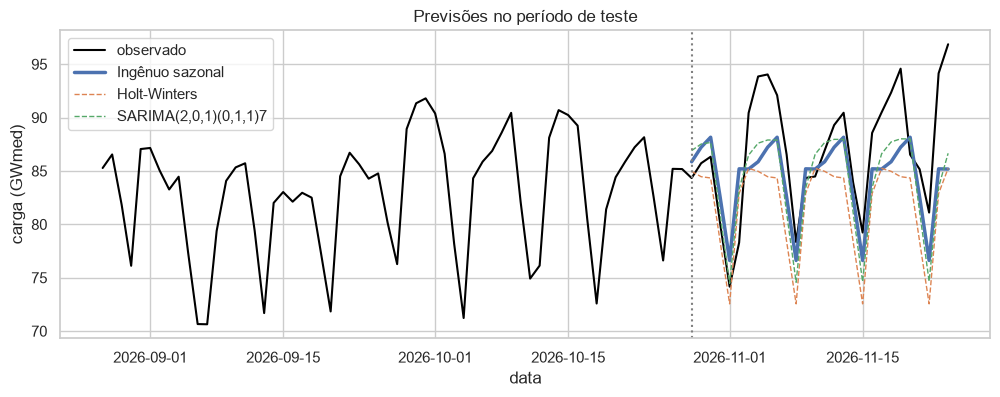

In [13]:
history = load.iloc[-90:]
plt.plot(history.index, history / 1000, color="black", label="observado")
for name, prediction in energy_predictions.items():
    width = 2.5 if name == best_energy else 1
    plt.plot(prediction.index, prediction / 1000, lw=width, ls="-" if name == best_energy else "--", label=name)
plt.axvline(test.index[0], color="gray", ls=":")
plt.title("Previsões no período de teste")
plt.xlabel("data")
plt.ylabel("carga (GWmed)")
plt.legend()
plt.show()

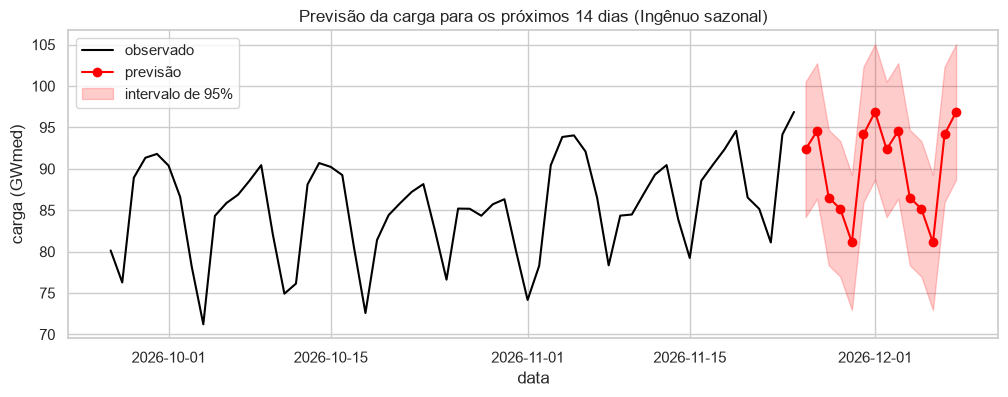

,previsão,limite inferior,limite superior
data,,,
2026-11-25,92.34,84.17,100.52
2026-11-26,94.58,86.40,102.76
2026-11-27,86.53,78.36,94.71
2026-11-28,85.16,76.98,93.34
2026-11-29,81.11,72.93,89.28
2026-11-30,94.15,85.97,102.32
2026-12-01,96.87,88.69,105.04
2026-12-02,92.34,84.17,100.52
2026-12-03,94.58,86.40,102.76


In [14]:
energy_errors = test - energy_predictions[best_energy]
energy_forecast = forecast_table(energy_models[best_energy](load, 14), energy_errors) / 1000
energy_forecast.index.name = "data"

recent = load.iloc[-60:] / 1000
plt.plot(recent.index, recent, color="black", label="observado")
plt.plot(energy_forecast.index, energy_forecast["previsão"], color="red", marker="o", label="previsão")
plt.fill_between(energy_forecast.index, energy_forecast["limite inferior"], energy_forecast["limite superior"],
                 color="red", alpha=0.2, label="intervalo de 95%")
plt.title(f"Previsão da carga para os próximos 14 dias ({best_energy})")
plt.xlabel("data")
plt.ylabel("carga (GWmed)")
plt.legend()
plt.show()
energy_forecast

### Conclusões do Problema 3

* **Componentes:** a demanda de energia do Brasil é formada por uma **tendência de crescimento**, uma
  **sazonalidade semanal** (domingo bem abaixo), uma **sazonalidade anual** (verão acima do inverno), um **ciclo
  diário** com pico às 19 h e um resíduo pequeno.
* **Previsão (28/10 a 24/11/2026):**
  * o ingênuo sazonal (MAPE **4,39%**) e o SARIMA (**4,42%**) praticamente empataram, e o SARIMA teve o menor RMSE;
  * o Holt-Winters ficou atrás (6,19%).

  O padrão semanal é tão forte que repetir a semana anterior já é uma referência difícil de superar.
* **Próximos 14 dias:** a carga prevista fica entre **81 e 97 GWmed**, com margem de cerca de ±8 GWmed.
* **Limitações e melhorias:**
  * os maiores erros (23 e 24/11/2026) aconteceram em dias de calor forte, que a série sozinha não antecipa;
  * incluir a **temperatura** e os **feriados** como variáveis deve reduzir o erro.

---
## Problema 13 — Chuvas para agricultura

**Objetivo:** descrever o regime de chuvas do Brasil, decompor a chuva mensal de cada região em componentes e prever
os próximos meses, para apoiar o planejamento agrícola (época de plantio e colheita).

### Dados

Fonte: INMET (Instituto Nacional de Meteorologia), estações meteorológicas automáticas de todo o Brasil, de 2018 a
2026. Há um arquivo por estação e por ano, com uma linha por hora.

**Cabeçalho de cada arquivo** (8 linhas de informações da estação):

| Campo | Significado |
|---|---|
| `REGIAO` | região do país: `N`, `NE`, `CO`, `SE` ou `S` |
| `UF` | estado |
| `ESTACAO` | nome da estação (normalmente o município) |
| `CODIGO (WMO)` | código da estação, como `A001` |
| `LATITUDE`, `LONGITUDE` | localização da estação, em graus |

**Colunas usadas:**

| Coluna | Significado |
|---|---|
| `Data` | dia da medição |
| `Hora UTC` | hora da medição no horário universal (horário de Brasília = UTC − 3 h) |
| `PRECIPITAÇÃO TOTAL, HORÁRIO (mm)` | chuva acumulada naquela hora, em milímetros. 1 mm = 1 litro de água por m² |

As demais colunas (pressão, temperatura, umidade e vento) não são usadas. O valor `-9999` indica que a estação não
mediu naquela hora.

**Tratamento:**
* cada arquivo é resumido em **chuva total por mês**, e um mês só vale se a estação mediu pelo menos **90% das horas**;
* a chuva de cada região é a **média das estações** da região naquele mês, considerando só meses com pelo menos 5
  estações válidas;
* a diferença entre UTC e o horário local é ignorada, porque afeta só as últimas 3 horas de cada mês.

In [15]:
def read_station(path):
    with open(path, encoding="latin-1") as file:
        header = [next(file).strip().split(";")[1] for _ in range(8)]
    return {
        "região": header[0],
        "uf": header[1],
        "estação": header[2],
        "código": header[3],
        "latitude": float(header[4].replace(",", ".")),
        "longitude": float(header[5].replace(",", ".")),
    }


def read_monthly_rain(path):
    data = pd.read_csv(path, sep=";", skiprows=8, usecols=[0, 2], encoding="latin-1", dtype=str)
    month = pd.to_datetime(data.iloc[:, 0].str[:7].str.replace("/", "-"))
    rain = pd.to_numeric(data.iloc[:, 1].str.replace(",", "."), errors="coerce")
    rain = rain.where((rain >= 0) & (rain <= 150))
    grouped = rain.groupby(month)
    monthly = pd.DataFrame({"chuva (mm)": grouped.sum(), "horas válidas": grouped.count() / grouped.size()})
    return monthly[monthly["horas válidas"] >= 0.9]["chuva (mm)"]


def load_rain(folder):
    rows = []
    for path in sorted(folder.rglob("*.CSV")):
        station = read_station(path)
        for month, rain in read_monthly_rain(path).items():
            rows.append({**station, "mês": month, "chuva (mm)": rain})
    return pd.DataFrame(rows)


rain = load_rain(RAIN_FOLDER)
print("Estações:", rain["código"].nunique())
print("Período:", rain["mês"].min().date(), "a", rain["mês"].max().date())
rain.groupby("região")["código"].nunique().to_frame("estações").T

Estações: 688
Período: 2018-01-01 a 2026-10-01


região,CO,N,NE,S,SE
estações,141,96,153,146,152


### Análise exploratória

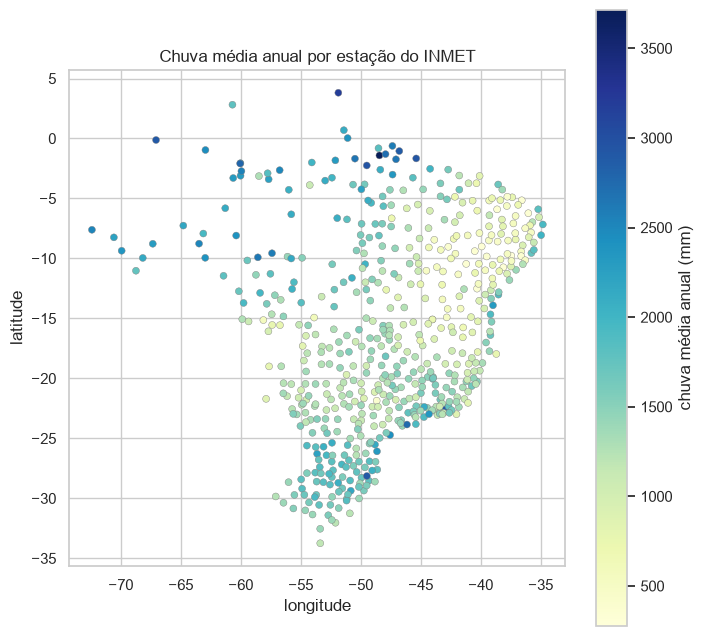

In [16]:
REGIONS = {"N": "Norte", "NE": "Nordeste", "CO": "Centro-Oeste", "SE": "Sudeste", "S": "Sul"}

stations = rain.groupby("código").agg(
    longitude=("longitude", "first"),
    latitude=("latitude", "first"),
    meses=("chuva (mm)", "size"),
    media_mensal=("chuva (mm)", "mean"),
)
stations = stations[stations["meses"] >= 24]
stations["chuva anual (mm)"] = stations["media_mensal"] * 12

plt.figure(figsize=(8, 8))
points = plt.scatter(stations["longitude"], stations["latitude"], c=stations["chuva anual (mm)"],
                     cmap="YlGnBu", s=25, edgecolor="gray", linewidth=0.3)
plt.colorbar(points, label="chuva média anual (mm)")
plt.title("Chuva média anual por estação do INMET")
plt.xlabel("longitude")
plt.ylabel("latitude")
plt.gca().set_aspect("equal")
plt.show()

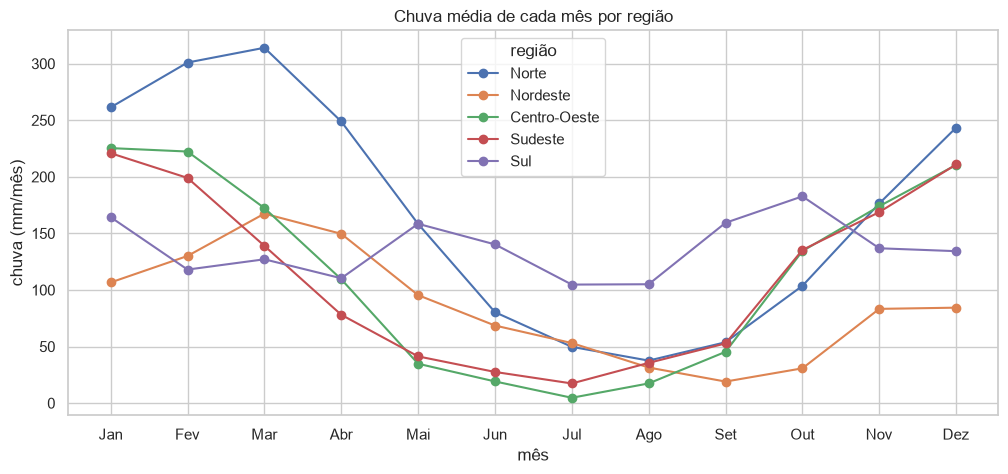

região,Norte,Nordeste,Centro-Oeste,Sudeste,Sul
chuva média anual (mm),"2,028.60","1,019.64","1,369.78","1,326.51","1,641.45"


In [17]:
region_rain = rain.groupby(["mês", "região"])["chuva (mm)"].agg(["mean", "count"])
region_rain = region_rain[region_rain["count"] >= 5]["mean"].unstack()[list(REGIONS)]
region_rain = region_rain.asfreq("MS")
region_rain = region_rain.fillna(region_rain.groupby(region_rain.index.month).transform("mean"))

climate = region_rain.groupby(region_rain.index.month).mean()
climate.index = MONTHS
climate.rename(columns=REGIONS).plot(marker="o", figsize=(12, 5))
plt.xticks(range(12), MONTHS)
plt.title("Chuva média de cada mês por região")
plt.xlabel("mês")
plt.ylabel("chuva (mm/mês)")
plt.legend(title="região")
plt.show()

totals = climate.sum().rename(REGIONS)
totals.to_frame("chuva média anual (mm)").T

**O que a análise exploratória mostra:**

* **Mapa:** a **Amazônia** (Norte) é a área mais chuvosa, com mais de 2.500 mm por ano em várias estações. O
  **semiárido nordestino** é a mais seca, com menos de 800 mm.
* **Média anual por região:** Norte ≈ 2.030 mm, Sul ≈ 1.640 mm, Centro-Oeste ≈ 1.370 mm, Sudeste ≈ 1.330 mm e
  Nordeste ≈ 1.020 mm.
* **Regimes de chuva bem diferentes:**
  * **Centro-Oeste e Sudeste:** estação chuvosa de **outubro a março** e seca forte de junho a agosto. No
    Centro-Oeste, julho tem cerca de 5 mm;
  * **Norte:** chove o ano todo, com pico em **março** (~315 mm) e mínimo em agosto;
  * **Nordeste:** chuvas concentradas de março a abril e período mais seco em setembro e outubro;
  * **Sul:** chuva **bem distribuída o ano inteiro**, entre ~105 e ~185 mm por mês, sem estação seca.
* **Para a agricultura:**
  * no Centro-Oeste e no Sudeste, a soja é plantada quando as chuvas se firmam (out–nov), e o milho safrinha
    depende das chuvas até abril;
  * no Sul, a chuva no inverno permite culturas como o trigo.

### Decomposição e estacionariedade

Cada região vira uma série de **chuva mensal**. Cada série é decomposta com o **STL** (período de 12 meses). Em seguida, são medidas a força da tendência e a da
sazonalidade anual, e é aplicado o teste ADF.

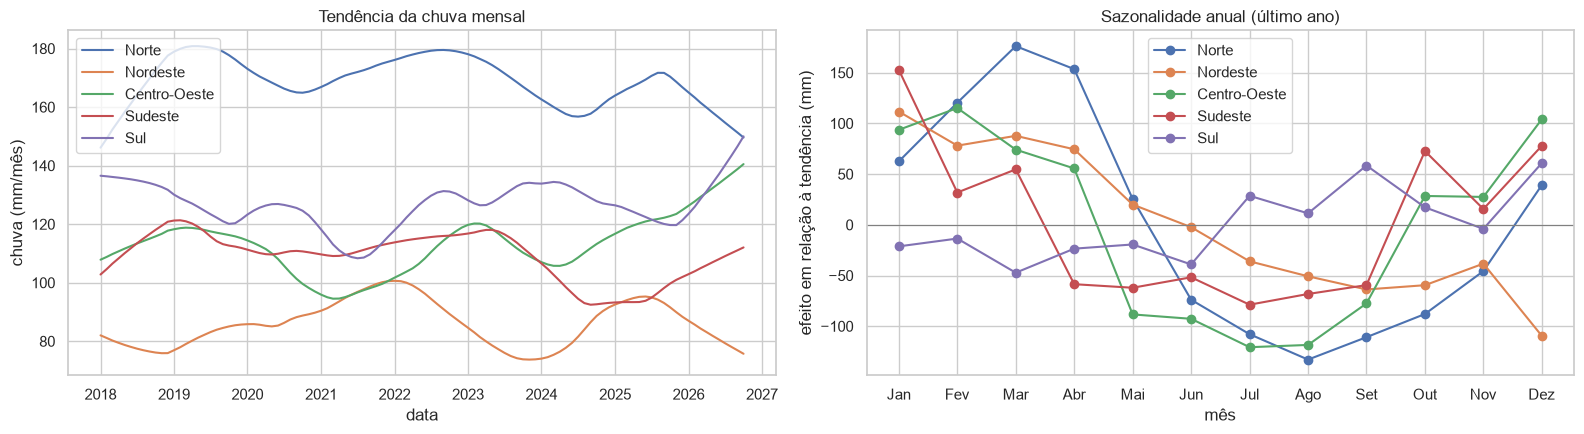

In [18]:
decompositions = {region: STL(region_rain[region], period=12, robust=True).fit() for region in REGIONS}

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for region, result in decompositions.items():
    axes[0].plot(result.trend.index, result.trend, label=REGIONS[region])
    seasonal = result.seasonal.iloc[-12:]
    axes[1].plot(MONTHS, seasonal.groupby(seasonal.index.month).mean().values, marker="o", label=REGIONS[region])
axes[0].set_title("Tendência da chuva mensal")
axes[0].set_xlabel("data")
axes[0].set_ylabel("chuva (mm/mês)")
axes[1].set_title("Sazonalidade anual (último ano)")
axes[1].set_xlabel("mês")
axes[1].set_ylabel("efeito em relação à tendência (mm)")
axes[1].axhline(0, color="gray", lw=0.8)
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

In [19]:
summary = pd.DataFrame({
    REGIONS[region]: {
        "força da tendência": strength(result.trend, result.resid),
        "força da sazonalidade anual": strength(result.seasonal, result.resid),
        **adf_test(region_rain[region]),
    }
    for region, result in decompositions.items()
}).T
summary

,força da tendência,força da sazonalidade anual,estatística ADF,p-valor,estacionária
Norte,0.10,0.91,-1.84,0.36,não
Nordeste,0.02,0.63,-7.91,0.00,sim
Centro-Oeste,0.00,0.87,-3.24,0.02,sim
Sudeste,0.02,0.79,-7.18,0.00,sim
Sul,0.07,0.19,-7.53,0.00,sim


**Interpretação:**

* **Sazonalidade anual:** é muito forte no **Norte (0,91)**, no **Centro-Oeste (0,87)** e no **Sudeste (0,79)**,
  média no **Nordeste (0,63)** e quase inexistente no **Sul (0,19)**. Isso confirma o que o gráfico de meses já
  mostrava.
* **Tendência:** a força é próxima de zero em todas as regiões (no máximo 0,10). Ou seja, em 9 anos não há aumento
  nem queda sistemática da chuva. As ondulações da curva de tendência são anos mais ou menos chuvosos, como a queda
  no Norte em 2023–2024, período da seca histórica na Amazônia.
* **Estacionariedade:**
  * quatro regiões são estacionárias pelo ADF (p < 0,05);
  * o **Norte não** (p ≈ 0,36), porque as oscilações de vários anos deixam o nível da série instável no período.

  A diferença sazonal do SARIMA (D = 1) trata esse caso.

### Previsão

Para cada região, os **últimos 12 meses** ficam separados como teste. São comparados quatro modelos:

| Modelo | Ideia |
|---|---|
| Climatologia | média histórica de cada mês |
| Ingênuo sazonal | repete o mesmo mês do ano anterior |
| Holt-Winters | suavização exponencial com sazonalidade anual |
| SARIMA(1,0,0)(0,1,1)₁₂ | diferença sazonal de 12 meses |

Previsões negativas são trocadas por zero. O modelo é escolhido pelo menor MAE; em caso de empate, fica o mais
simples (a ordem da tabela acima).

In [20]:
def rain_climatology(train, steps):
    index = future_index(train, steps)
    means = train.groupby(train.index.month).mean()
    return pd.Series(means.loc[index.month].values, index=index)


def rain_naive(train, steps):
    return seasonal_naive(train, steps, 12)


def rain_holt_winters(train, steps):
    model = ExponentialSmoothing(train, seasonal="add", seasonal_periods=12).fit()
    return model.forecast(steps).clip(lower=0)


def rain_sarima(train, steps):
    model = SARIMAX(train, order=(1, 0, 0), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
    return model.forecast(steps).clip(lower=0)


rain_models = {
    "Climatologia": rain_climatology,
    "Ingênuo sazonal": rain_naive,
    "Holt-Winters": rain_holt_winters,
    "SARIMA(1,0,0)(0,1,1)12": rain_sarima,
}

rain_results = {}
for region in REGIONS:
    series = region_rain[region]
    predictions, scores = compare_models(rain_models, series.iloc[:-12], series.iloc[-12:])
    best = scores["MAE"].round(1).reindex(list(rain_models)).idxmin()
    rain_results[region] = {"predictions": predictions, "scores": scores, "best": best}

print("Teste:", region_rain.index[-12].date(), "a", region_rain.index[-1].date())
rain_mae = pd.DataFrame({REGIONS[region]: result["scores"]["MAE"] for region, result in rain_results.items()}).T
rain_mae = rain_mae[list(rain_models)]
rain_mae["melhor modelo"] = [result["best"] for result in rain_results.values()]
rain_mae

Teste: 2025-11-01 a 2026-10-01


,Climatologia,Ingênuo sazonal,Holt-Winters,"SARIMA(1,0,0)(0,1,1)12",melhor modelo
Norte,31.64,34.02,29.31,30.23,Holt-Winters
Nordeste,19.69,35.73,19.69,19.53,"SARIMA(1,0,0)(0,1,1)12"
Centro-Oeste,20.99,38.82,20.99,24.12,Climatologia
Sudeste,41.30,69.32,41.30,44.17,Climatologia
Sul,47.62,46.33,46.53,46.06,"SARIMA(1,0,0)(0,1,1)12"


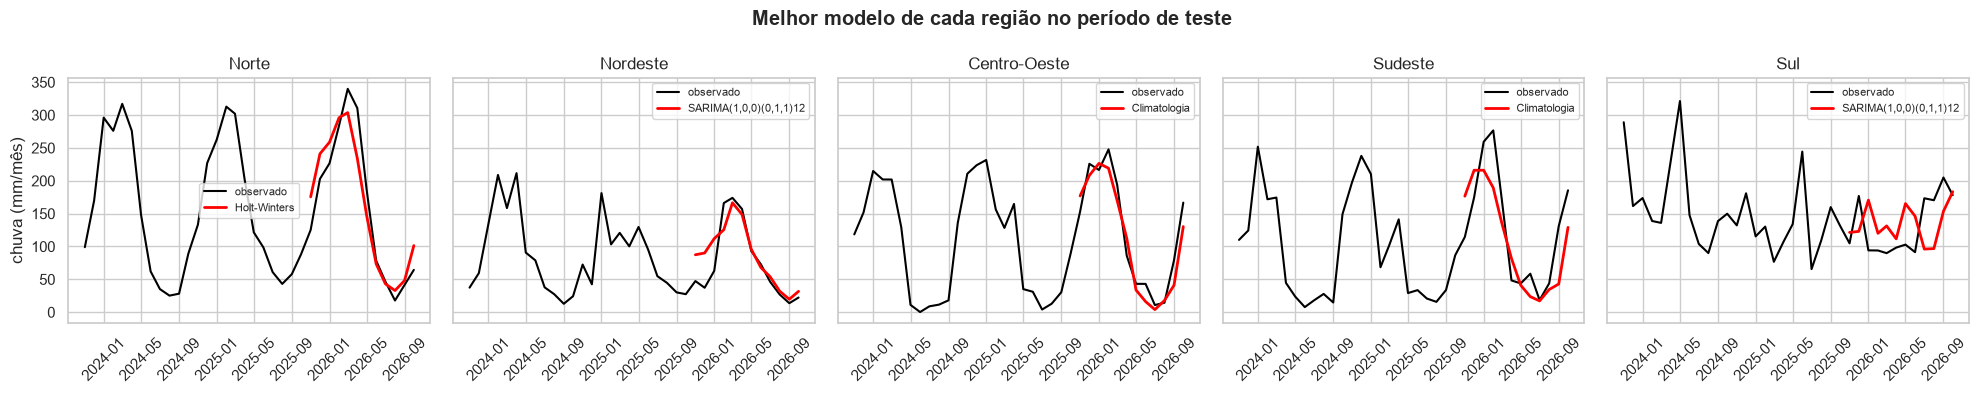

In [21]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)
for ax, (region, result) in zip(axes, rain_results.items()):
    history = region_rain[region].iloc[-36:]
    prediction = result["predictions"][result["best"]]
    ax.plot(history.index, history, color="black", label="observado")
    ax.plot(prediction.index, prediction, color="red", lw=2, label=result["best"])
    ax.set_title(REGIONS[region])
    ax.tick_params(axis="x", rotation=45)
    ax.legend(fontsize=8)
axes[0].set_ylabel("chuva (mm/mês)")
fig.suptitle("Melhor modelo de cada região no período de teste", fontweight="bold")
plt.tight_layout()
plt.show()

In [22]:
rain_forecast = {}
for region, result in rain_results.items():
    series = region_rain[region]
    forecast = rain_models[result["best"]](series, 6)
    rain_forecast[REGIONS[region]] = forecast.round().astype(int)

rain_forecast = pd.DataFrame(rain_forecast).T
rain_forecast.columns = [f"{MONTHS[date.month - 1]}/{date.year}" for date in rain_forecast.columns]
rain_forecast.index.name = "previsão de chuva (mm)"
rain_forecast

,Nov/2026,Dez/2026,Jan/2027,Fev/2027,Mar/2027,Abr/2027
previsão de chuva (mm),,,,,,
Norte,164,231,250,289,303,237
Nordeste,81,83,107,130,167,150
Centro-Oeste,174,210,225,222,172,109
Sudeste,169,211,221,199,139,78
Sul,136,137,161,118,126,112


### Conclusões do Problema 13

* **Componentes:** a chuva mensal de cada região é basicamente um **ciclo anual** sem tendência, somado a uma
  variação aleatória entre os anos. O ciclo é forte no Norte, no Centro-Oeste e no Sudeste e fraco no Sul.
* **Previsão (nov/2025 a out/2026):**
  * no **Centro-Oeste** e no **Sudeste**, a **climatologia** (média histórica do mês) foi a melhor;
  * no **Norte** venceu o Holt-Winters e no **Nordeste** o SARIMA, mas por pouco: menos de 3 mm/mês de diferença
    para a climatologia;
  * repetir o ano anterior (ingênuo sazonal) foi o pior modelo em 4 das 5 regiões;
  * no **Sul**, todos os modelos erram cerca de 46–48 mm/mês, porque sem ciclo anual a chuva é pouco previsível.

  Conclusão: **além do ciclo anual, o histórico da própria série quase não ajuda a prever a chuva de um mês.**
* **Previsão para a safra 2026/27:** no **Centro-Oeste**, ~174 mm em novembro, subindo para ~225 mm em janeiro e
  caindo para ~109 mm em abril. É o mesmo calendário de plantio da soja em out–nov e colheita em fev–mar. O Sudeste
  segue o mesmo padrão, o Norte tem pico em março e o Sul fica estável.
* **Limitações e melhorias:**
  * a média de uma região mistura climas diferentes (no Nordeste, o litoral e o semiárido);
  * o número de estações muda com o tempo, e há uma única janela de teste;
  * para prever melhor seriam necessárias variáveis externas, como El Niño/La Niña.

---
## Referências

* ONS — Histórico da Operação, Curva de Carga Horária: <https://www.ons.org.br/Paginas/resultados-da-operacao/historico-da-operacao>
* ONS — Subsistemas do SIN: <https://www.ons.org.br/paginas/sobre-o-sin/o-que-e-o-sin>
* INMET — Dados Históricos: <https://portal.inmet.gov.br/dadoshistoricos>